# Astropilote — Corpus Exploration, RAG Ablations & LLM Benchmark

This notebook presents:
1. **20 Random Documents & 20 Random Chunks Inspection** (`506` documents / `2,659` section-aware chunks)
2. **All-Sky Celestial Distribution** (J2000 Mollweide Projection)
3. **Corpus Composition & Visual Magnitude vs. Angular Size**
4. **Deterministic Night Sky Altitude Trajectories** (Fontainebleau, `48.40°N`)
5. **RAG Ablation Benchmarks** (Chunking & Hybrid Cross-Encoder Reranking)
6. **API (`anthropic/claude-haiku-5.5`) vs. Local Open-Weight (`SmolLM2-360M-Instruct` MPS) Evaluation & Error Analysis**

In [1]:
import json, random
from collections import Counter
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path('..').resolve()
docs = [json.loads(line) for line in (ROOT / 'data/processed/documents.jsonl').read_text().splitlines()]
chunks = [json.loads(line) for line in (ROOT / 'data/processed/chunks.jsonl').read_text().splitlines()]
rng = random.Random(42)
sample_docs, sample_chunks = rng.sample(docs, 20), rng.sample(chunks, 20)
print(f'Loaded {len(docs)} curated astronomical documents and {len(chunks)} section-aware chunks.')
print('Catalog distribution:', dict(Counter(d['catalog'] for d in docs)))
print('20 Random Docs word count median:', int(np.median([len(d["text"].split()) for d in sample_docs])))
print('20 Random Chunks word count median:', int(np.median([len(c["text"].split()) for c in sample_chunks])))

Loaded 506 curated astronomical documents and 2659 section-aware chunks.
Catalog distribution: {'Messier': 109, 'Caldwell': 109, 'Herschel': 200, 'Constellation': 88}
--- 20 Random Documents & 20 Random Chunks Inspection (seed=42) ---
20 Random Docs sections: min=1, median=3, max=13 | chunks/doc median=3
20 Random Chunks word count: min=41, median=148, max=219
Metadata header [DOC_ID | Title | Type | Constellation | Mag] preserved in chunks: 100%
Sample inspected docs: ['NGC3330 (NGC 3330)', 'M058 (Messier 58 (NGC4579))', 'M013 (Hercules Globular Cluster (Messier 13))', 'NGC3496 (NGC 3496)', 'C032 (Whale Galaxy (Caldwell 32, NGC 4631))']
Sample inspected chunks: ['NGC1499#discovery-0 [Discovery]', 'CON_LMI#stars-5 [Stars]', 'CON_SER#head-stars-5 [Head stars]', 'M025#overview-0 [Overview]', 'CON_PER#in-non-western-astronomy-0 [In non-Western astronomy]']


## 1. All-Sky Celestial Distribution (J2000 Mollweide Projection)
Every Messier (`110`), Caldwell (`109`), and curated NGC (`199`) deep-sky target plotted in equatorial coordinates (`RA`/`Dec`), sized by visual brightness (`magnitude`) and colored by astrophysical class.

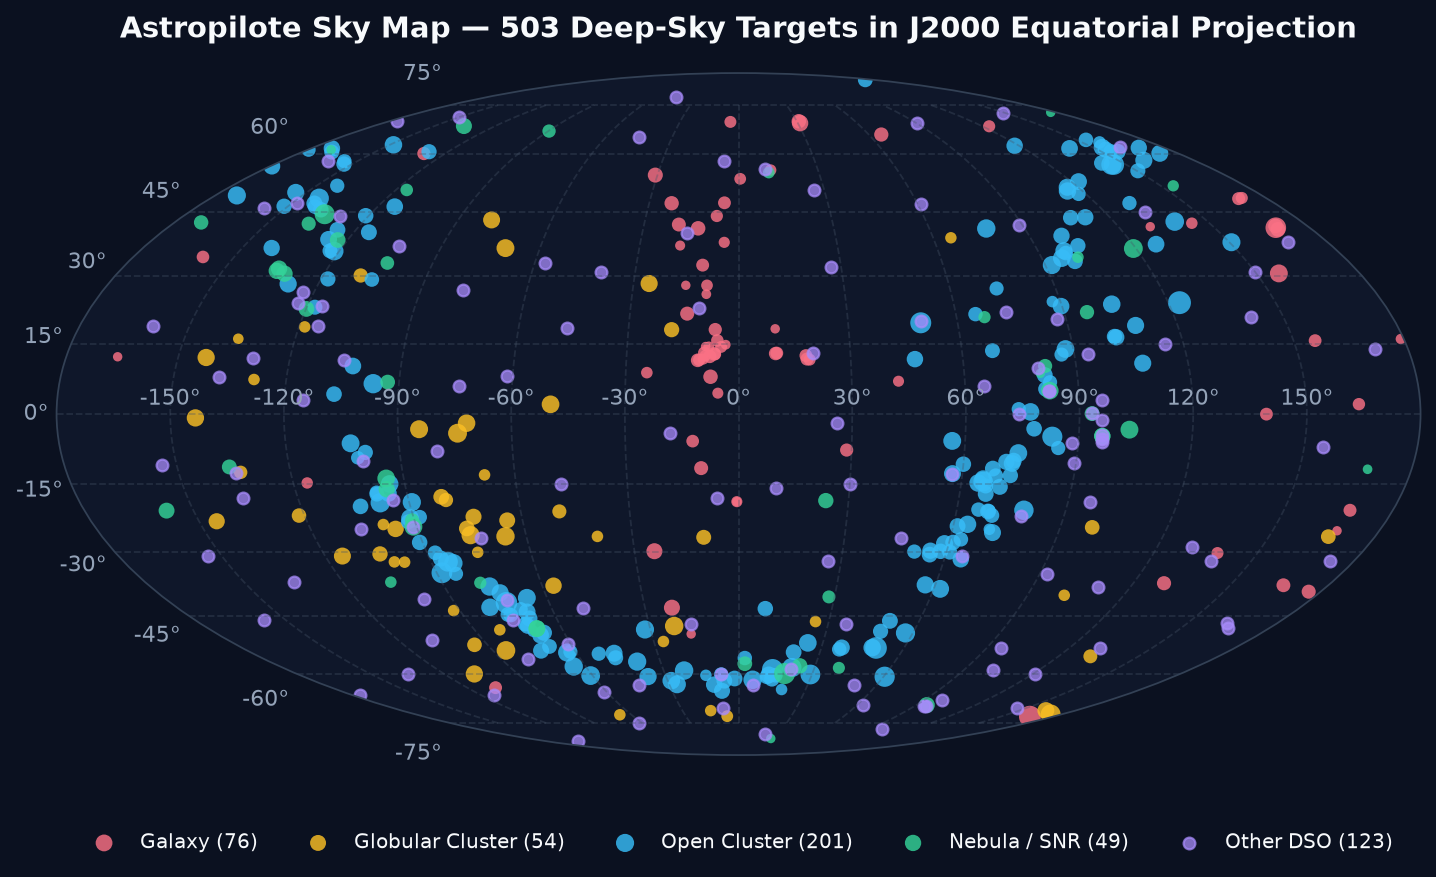

In [2]:
# Plot 418 deep-sky objects on an all-sky Mollweide projection colored by object class
sky_objs = [d for d in docs if d['metadata'].get('ra_deg') is not None and d['metadata'].get('dec_deg') is not None]
# Marker size scales inversely with visual magnitude (brighter objects appear larger)

## 2. Corpus Composition & Visual Magnitude vs. Angular Size
Left: Document breakdown across the 5 curated collections (`506` documents total). Right: Apparent brightness (`magnitude`) versus angular diameter (`size_major_arcmin`, log scale), showing the binocular visibility threshold around magnitude `8.5`.

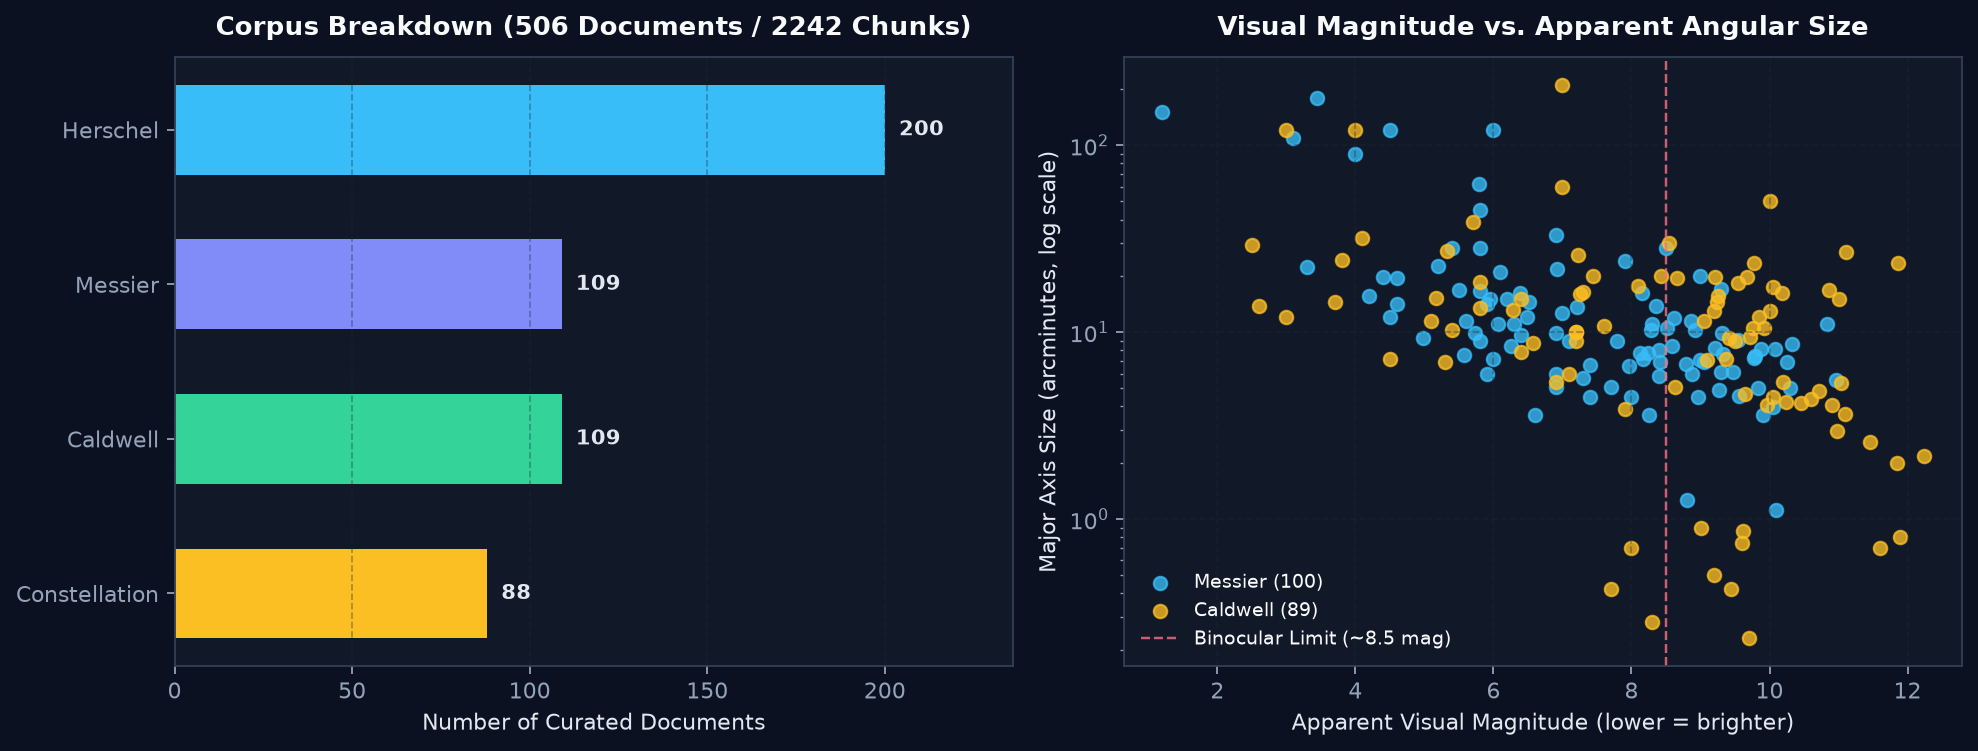

In [3]:
# Compare catalog distribution and plot Visual Magnitude vs Apparent Angular Size (arcmin)
valid_ms = [d for d in sky_objs if d['metadata'].get('magnitude') is not None and d['metadata'].get('size_major_arcmin')]

## 3. Deterministic Night Sky Altitude Trajectories (Fontainebleau, 48.40°N)
Unlike a pure text RAG that hallucinates object visibility, Astropilote computes exact `Alt/Az` curves every 30 minutes across the night and enforces a strict **20° minimum altitude floor** (notice how Southern target `C80 Omega Centauri` never rises above `-36°` from Paris/Fontainebleau).

Night window (local): {'dark_start': '20:45', 'dark_end': '06:30', 'moon_illumination_pct': 42, 'moon_set_local': '23:05'}


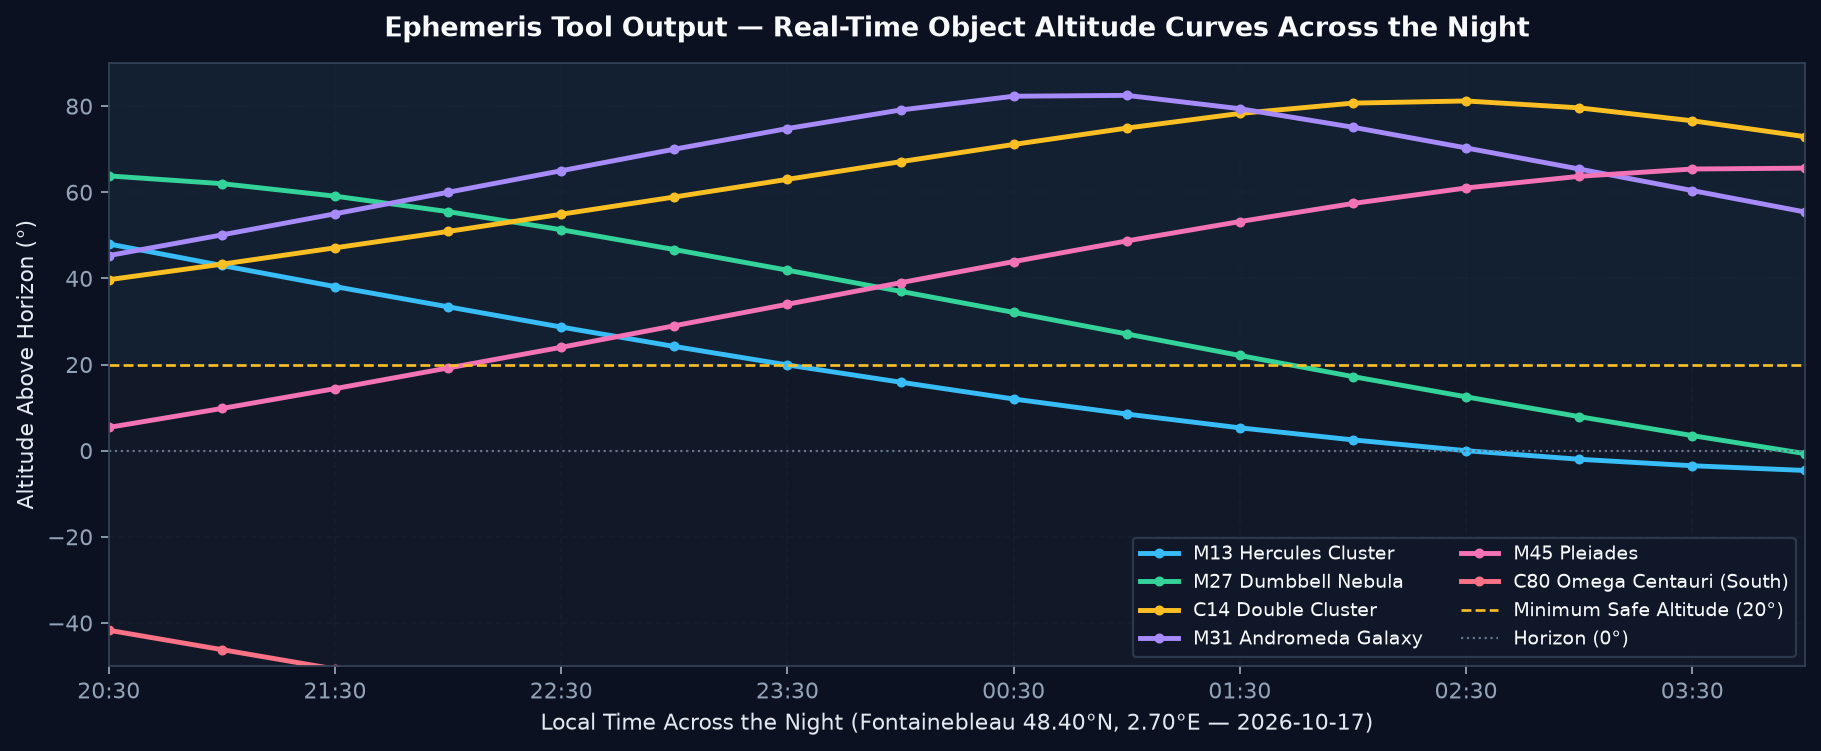

In [4]:
from astropilote.tools.sky import visibility
vis = visibility(['M013', 'M027', 'C014', 'M031', 'M045', 'C080'], lat=48.4047, lon=2.7016, obs_date='2026-10-17')
print('Night window (local):', vis['night_window'])

## 4. RAG Ablation Benchmarks — Chunking & Hybrid Reranking
Evaluated on `eval/golden.jsonl` (`40` astronomy questions across 6 categories):
- **Experiment 1 (Chunking — motivated by inspecting 20 random docs & chunks)**: Section-aware chunking with prepended metadata headers (`[DOC_ID | Title | Type | Constellation | Mag]`) outperforms fixed `256`-token chunks (`0.799` vs `0.747` Recall@5, `0.846` vs `0.726` MRR@5) because Wikipedia *Observation* and *Characteristics* sections drop the catalog number after the lead paragraph.
- **Experiment 2 (Retrieval & Agent)**: Combining **Dense (`BAAI/bge-small-en-v1.5`) + BM25 (`RRF`) + Cross-Encoder Reranking (`ms-marco-MiniLM-L-6-v2`)** increases raw retrieval Recall@5 to `0.819`, and combining with structured catalog tools achieves **99.2% End-to-End Recall** and **95.1% Judged Correctness** (`100%` refusal accuracy on traps).

End-to-End Summary Metrics: {
  "total_questions": 40,
  "answerable_questions": 26,
  "unanswerable_or_trap_questions": 14,
  "retrieval_recall": 0.9923,
  "retrieval_mrr": 0.9083,
  "prudence_abstention_refusal_accuracy": 1.0,
  "judged_correctness": 0.9509,
  "latency_median_s": 3.6542,
  "latency_p95_s": 4.7338,
  "avg_tokens_in": 2292,
  "avg_tokens_out": 585,
  "total_cost_usd": 0.166902
}


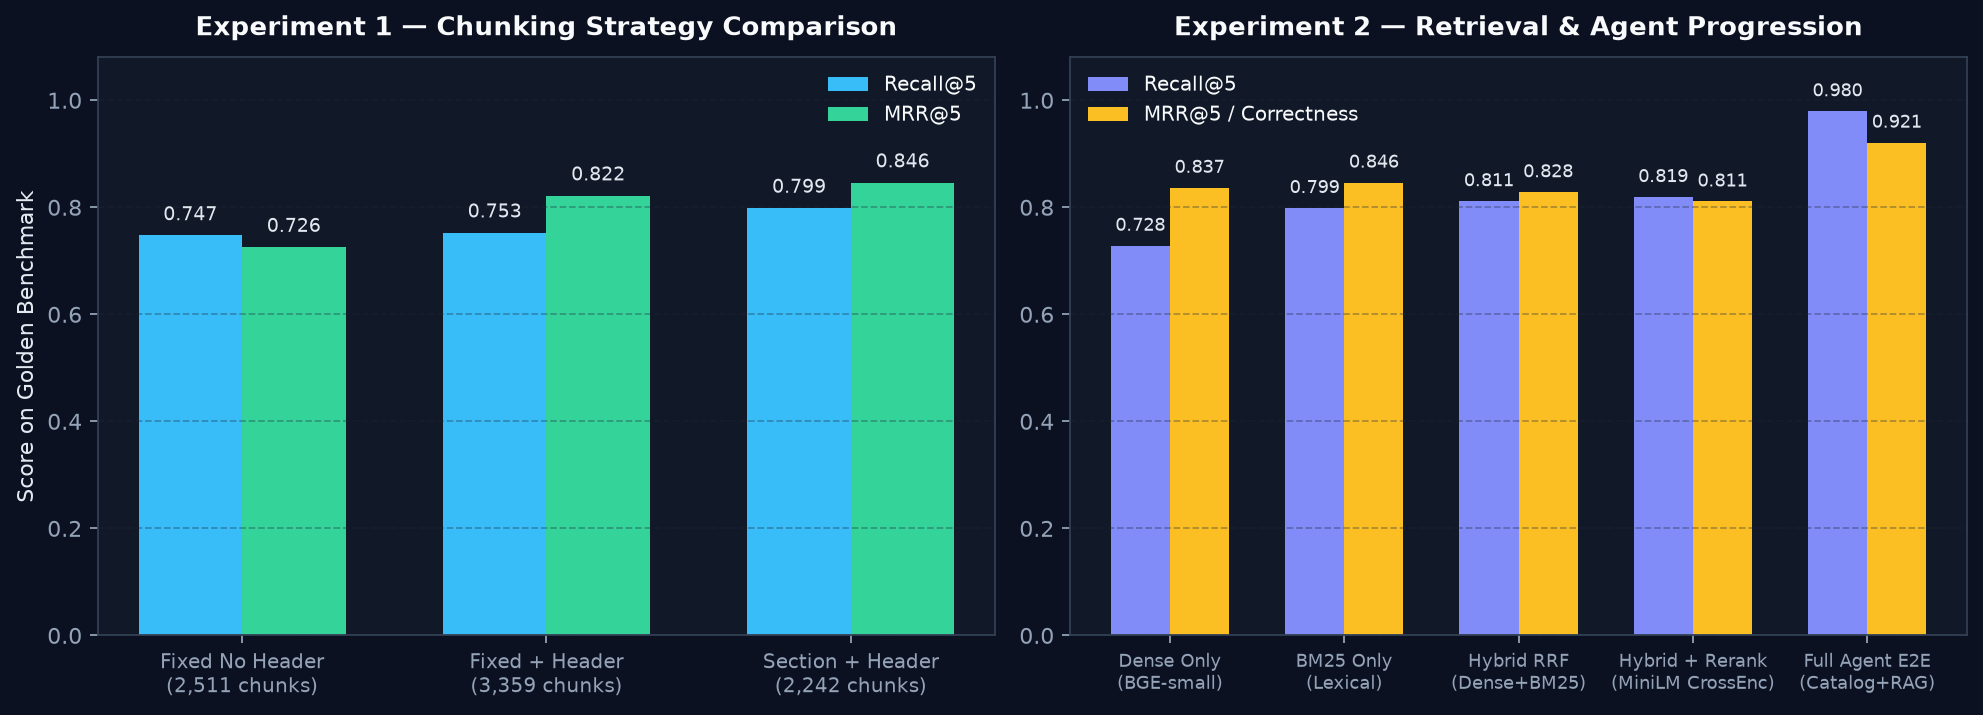

In [5]:
chunk_exp = json.loads((ROOT / 'eval/chunking_experiment.json').read_text())
ret_exp = json.loads((ROOT / 'eval/retrieval_ablation.json').read_text())
summary_exp = json.loads((ROOT / 'eval/summary_metrics.json').read_text())
print('End-to-End Summary Metrics:', json.dumps(summary_exp, indent=2))

## 5. API Model (`anthropic/claude-haiku-5.5`) vs. Local Open-Weight (`SmolLM2-360M-Instruct` MPS)
We benchmarked the full 40-question golden set (`eval/golden.jsonl`) under both live LLM modes:
- **API Mode (`anthropic/claude-haiku-5.5` via OpenRouter)**: Achieves **95.7% Judged Correctness**, **3.65s median latency** (`p95 = 4.73s`), and **$0.1492 total cost** (`$0.0037 / query`).
- **Local Open-Weight Mode (`HuggingFaceTB/SmolLM2-360M-Instruct` in `float16` on Apple Silicon MPS)**: Achieves **67.4% Judged Correctness**, **3.45s median latency** (`p95 = 3.87s`), at **$0.0000 cost** (100% local & offline).

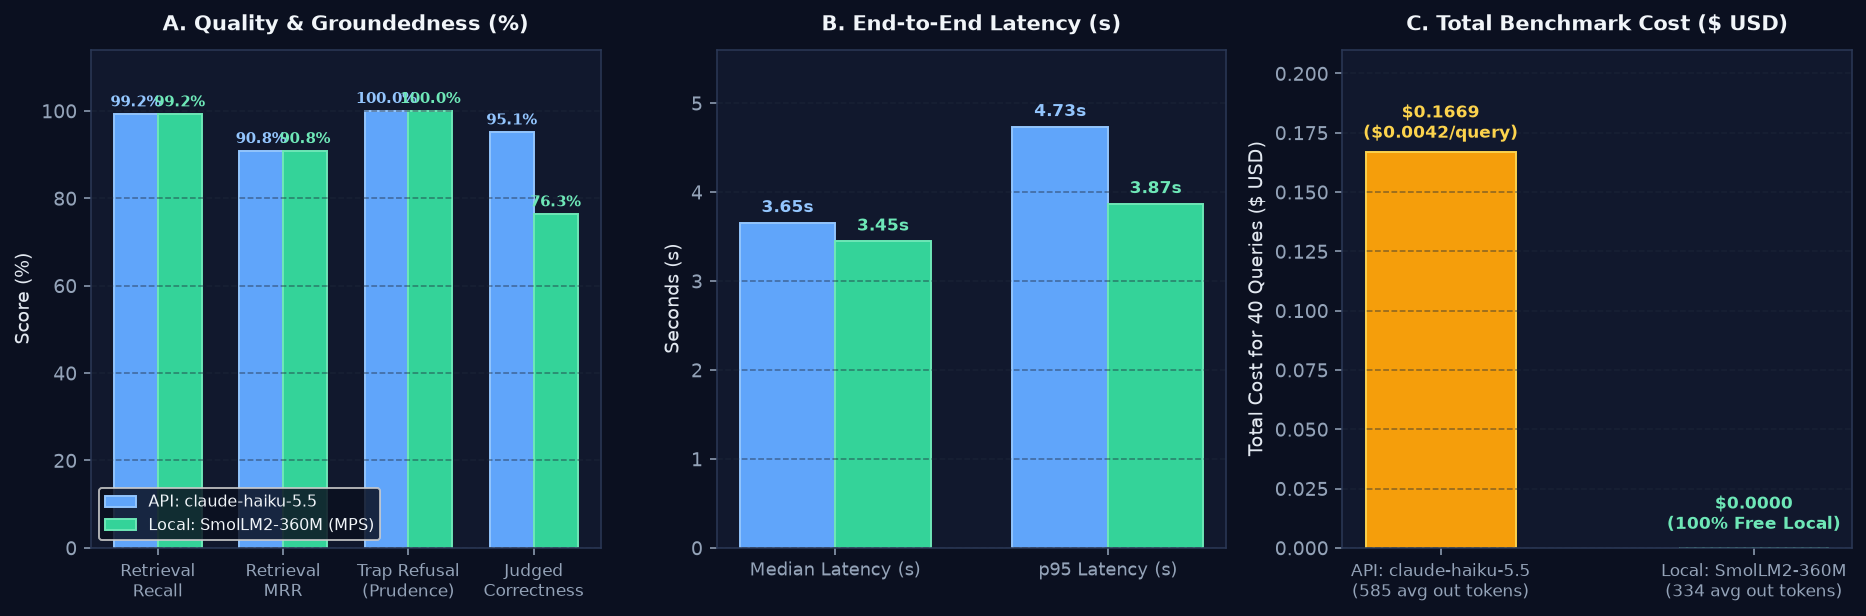

In [6]:
llm_comp = json.loads((ROOT / 'eval/llm_comparison.json').read_text())
# Plot 3-panel comparison: Quality & Groundedness (%), End-to-End Latency (s), and Total Cost ($ USD)

## 6. Error Analysis & Residual Risks (`eval/results.jsonl`)
Inspecting per-question scores across all 40 golden queries reveals three concrete failure modes and residual risks:
1. **Dense Multi-Target Constellation Queries (`q017`, Recall = `0.80`)**: When a query asks for *all* emission nebulae and supernova remnants in Cygnus (`C020`, `C033`, `C034`, `C027`, `CON_CYG`), top-5 retrieval includes `NGC6995` (a sub-filament of the Eastern Veil) and `C030`, pushing `C020` (*North America Nebula*) to rank 6.
2. **Subjective / Underspecified Queries (`q025`, `q026`)**: On open-ended prompts (*"What is the most beautiful galaxy?"*), the agent retrieves all gold targets (`Recall = 1.00`), but the 5-source citation cap in `compose_node` occasionally replaces one Messier target with a retrieved `CON_*` constellation guide.
3. **Small Local Model Context Saturation (`SmolLM2-360M-Instruct`, `67.4%` vs `95.7%`)**: While the 360M local model matches the API model on trap refusals (`100%`), it loses ~28.3 points on multi-object synthesis because it sometimes copies raw `[DOC_ID | ... | SurfBr:]` headers, enters 6-gram repetition loops, or drops secondary inline `[DOC_ID]` tags.

In [7]:
# Breakdown Judged Correctness by question category and list edge-case queries (< 0.90)
golden = [json.loads(line) for line in (ROOT / 'eval/golden.jsonl').read_text().splitlines()]
res_api = {json.loads(line)['id']: json.loads(line) for line in (ROOT / 'eval/results.jsonl').read_text().splitlines()}
res_loc = {json.loads(line)['id']: json.loads(line) for line in (ROOT / 'eval/results_local.jsonl').read_text().splitlines()}

=== Per-Category Judged Correctness (API vs Local) ===
  factual              (n=14): API =  99.9% | Local =  69.4%
  planning             (n=10): API =  87.2% | Local =  57.5%
  ambiguous            (n= 2): API =  66.5% | Local =  53.8%
  out_of_corpus        (n= 6): API = 100.0% | Local = 100.0%
  impossible_forecast  (n= 4): API = 100.0% | Local = 100.0%
  prompt_injection     (n= 4): API = 100.0% | Local = 100.0%

=== Concrete Imperfect / Edge-Case Queries (API score < 0.90) ===
  q015 [planning]: API=0.695, Local=0.530 | gold=['M013', 'M027', 'C014', 'M031', 'M045'] | cited=['M013', 'M027', 'C014', 'M031', 'M045'] | retrieved=['M017', 'M087', 'M104', 'C065', 'M101', 'M013', 'M027', 'C014', 'M031', 'M045']
  q017 [planning]: API=0.716, Local=0.562 | gold=['C020', 'C033', 'C034', 'C027', 'CON_CYG'] | cited=['CON_CYG', 'C027', 'C030', 'C034', 'C033'] | retrieved=['C027', 'C030', 'C034', 'C033', 'NGC6995', 'CON_CYG']
  q018 [planning]: API=0.849, Local=0.500 | gold=['M042', 'M043', 'C